In [1]:
import pandas as pd
import numpy as np
import missingno as msno
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
path = r'../../data/limpieza/cleaned_data.csv'
df = pd.read_csv(path, header=0)
df['timestamp'] = pd.to_datetime(df['timestamp'])
df

,timestamp,open_binance,high_binance,low_binance,close_binance,volumen_binance,trades_binance,var_diaria_binance,rango_dia_binance,volatilidad_50_binance,...,momentum_200_dxy,SMA_50_dxy,EMA_50_dxy,SMA_200_dxy,EMA_200_dxy,RSI_dxy,pct_cambio_7d,tendencia_futura_7d,pct_cambio_30d,tendencia_futura_30d
0,2023-01-01,16541.77,16628.00,16499.01,16616.75,96925.41374,3218355.0,0.449451,128.99,367.529453,...,-1.084069,105.275233,105.547776,107.887225,106.544019,41.998608,NaN,0,NaN,0
1,2023-01-02,16617.17,16799.23,16548.70,16672.87,121888.57191,4036118.0,0.337732,250.53,362.064797,...,0.617581,105.229899,105.497667,107.890425,106.521392,45.834443,NaN,0,NaN,0
2,2023-01-03,16672.78,16778.40,16605.28,16675.18,159541.53733,5097596.0,0.013855,173.12,361.616039,...,-0.171920,105.187099,105.459327,107.889525,106.501478,49.435670,NaN,0,NaN,0
3,2023-01-04,16675.65,16991.87,16652.66,16850.36,220362.18862,6310703.0,1.050543,339.21,361.374263,...,-0.367944,105.144099,105.411903,107.887600,106.479075,45.887346,NaN,0,NaN,0
4,2023-01-05,16850.36,16879.82,16753.00,16831.85,163473.56641,4842014.0,-0.109849,126.82,360.953339,...,0.449461,105.119299,105.397318,107.889950,106.464756,55.868588,NaN,0,NaN,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
796,2025-03-07,89931.88,91283.02,84667.03,86801.75,57980.35713,9510442.0,-3.480567,6615.99,6079.215982,...,1.913826,107.378100,107.025031,105.306625,106.166551,23.284185,NaN,0,NaN,0
797,2025-03-08,86801.74,86897.25,85218.47,86222.45,12989.23054,2553974.0,-0.667383,1678.78,6168.585303,...,1.913826,107.378100,107.025031,105.306625,106.166551,23.284185,NaN,0,NaN,0
798,2025-03-09,86222.46,86500.00,80000.00,80734.37,26115.39345,5189138.0,-6.365024,6500.00,6445.301805,...,1.913826,107.378100,107.025031,105.306625,106.166551,23.284185,NaN,0,NaN,0
799,2025-03-10,80734.48,84123.46,79332.00,80104.40,24622.30310,4965411.0,-0.780300,4791.46,6777.296313,...,1.913826,107.378100,107.025031,105.306625,106.166551,23.284185,NaN,0,NaN,0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 801 entries, 0 to 800
Data columns (total 93 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   timestamp                  801 non-null    datetime64[ns]
 1   open_binance               801 non-null    float64       
 2   high_binance               801 non-null    float64       
 3   low_binance                801 non-null    float64       
 4   close_binance              801 non-null    float64       
 5   volumen_binance            801 non-null    float64       
 6   trades_binance             801 non-null    float64       
 7   var_diaria_binance         801 non-null    float64       
 8   rango_dia_binance          801 non-null    float64       
 9   volatilidad_50_binance     801 non-null    float64       
 10  momentum_50_binance        801 non-null    float64       
 11  volatilidad_200_binance    801 non-null    float64       
 12  momentum

In [4]:
df.describe()

,timestamp,open_binance,high_binance,low_binance,close_binance,volumen_binance,trades_binance,var_diaria_binance,rango_dia_binance,volatilidad_50_binance,...,momentum_200_dxy,SMA_50_dxy,EMA_50_dxy,SMA_200_dxy,EMA_200_dxy,RSI_dxy,pct_cambio_7d,tendencia_futura_7d,pct_cambio_30d,tendencia_futura_30d
count,801,801.000000,801.000000,801.000000,801.000000,801.000000,8.010000e+02,801.000000,801.000000,801.000000,...,801.000000,801.000000,801.000000,801.000000,801.000000,801.000000,788.000000,801.000000,742.000000,801.000000
mean,2024-02-04 23:58:12.134831616,51594.406317,52630.306654,50571.847453,51672.977740,64452.214983,2.859805e+06,0.228755,2058.459201,3414.059061,...,-0.539507,104.104421,104.125212,104.317839,104.214243,51.243442,1.616158,0.157303,6.771095,0.299625
min,2023-01-01 00:00:00,16541.770000,16628.000000,16499.010000,16616.750000,7047.904300,3.108520e+05,-8.538655,73.910000,336.687863,...,-11.236414,101.219900,101.456896,102.709050,102.903176,19.711828,-12.802918,-1.000000,-11.118419,-1.000000
25%,2023-07-20 00:00:00,28165.470000,28631.010000,27666.950000,28170.010000,23185.047590,1.047056e+06,-1.034257,795.000000,1641.754283,...,-2.219430,102.823132,102.952850,103.757725,103.656685,40.255529,-2.031303,-1.000000,-2.397357,-1.000000
50%,2024-02-05 00:00:00,45288.660000,47248.990000,44300.360000,46110.000000,33595.696370,1.658863e+06,0.018674,1520.000000,3045.426551,...,-0.210931,103.836668,103.825209,104.039675,104.082171,50.771474,0.819749,1.000000,3.859773,1.000000
75%,2024-08-23 00:00:00,67210.000000,68366.660000,65857.250000,67314.240000,53435.293310,3.762755e+06,1.384561,2727.350000,3852.013502,...,1.926993,105.084467,105.073326,104.504726,104.610459,62.615332,4.071766,1.000000,13.829234,1.000000
max,2025-03-10 00:00:00,106143.820000,109588.000000,105321.490000,106143.820000,699360.934230,1.522359e+07,11.883431,13588.000000,12637.123266,...,5.058973,108.462400,108.063136,107.890425,106.544019,82.759709,22.108965,1.000000,39.508978,1.000000
std,NaN,24918.815526,25453.124577,24304.451687,24907.338536,94769.473342,2.750940e+06,2.568455,1775.514588,2541.005739,...,3.280603,1.716001,1.584861,1.223958,0.850790,14.043421,5.813711,0.979911,12.046046,0.915212


## 1. Conteo de nulos

<Axes: >

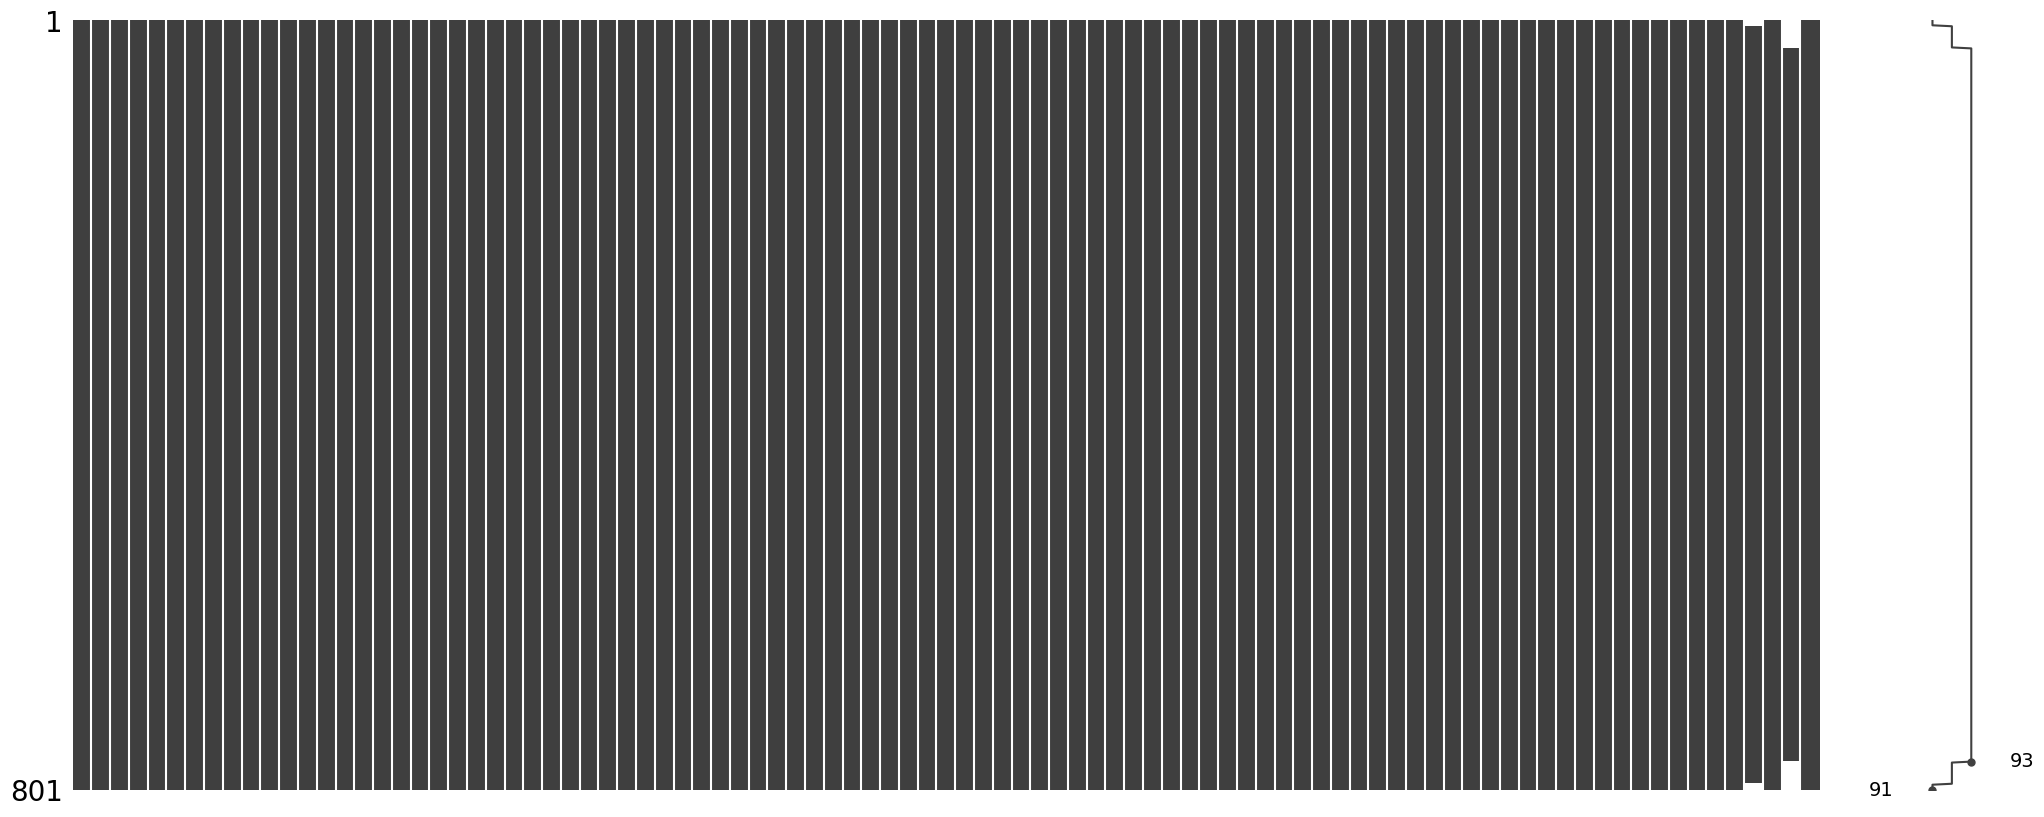

In [5]:
msno.matrix(df)

## 2. Correlaciones

### Relación precios de Bitcoin con otros activos (S&P 500, DXY, Nasdaq)

In [6]:
corr_matrix = df[['open_binance', 'high_binance', 'low_binance', 'close_binance', 'volumen_binance', 'trades_binance',
                 'close_sp500', 'high_sp500', 'low_sp500', 'open_sp500', 'volume_sp500',
                 'close_nasdaq', 'high_nasdaq', 'low_nasdaq', 'open_nasdaq', 'volume_nasdaq',
                 'close_dxy', 'high_dxy', 'low_dxy', 'open_dxy']].dropna().corr(method='pearson')

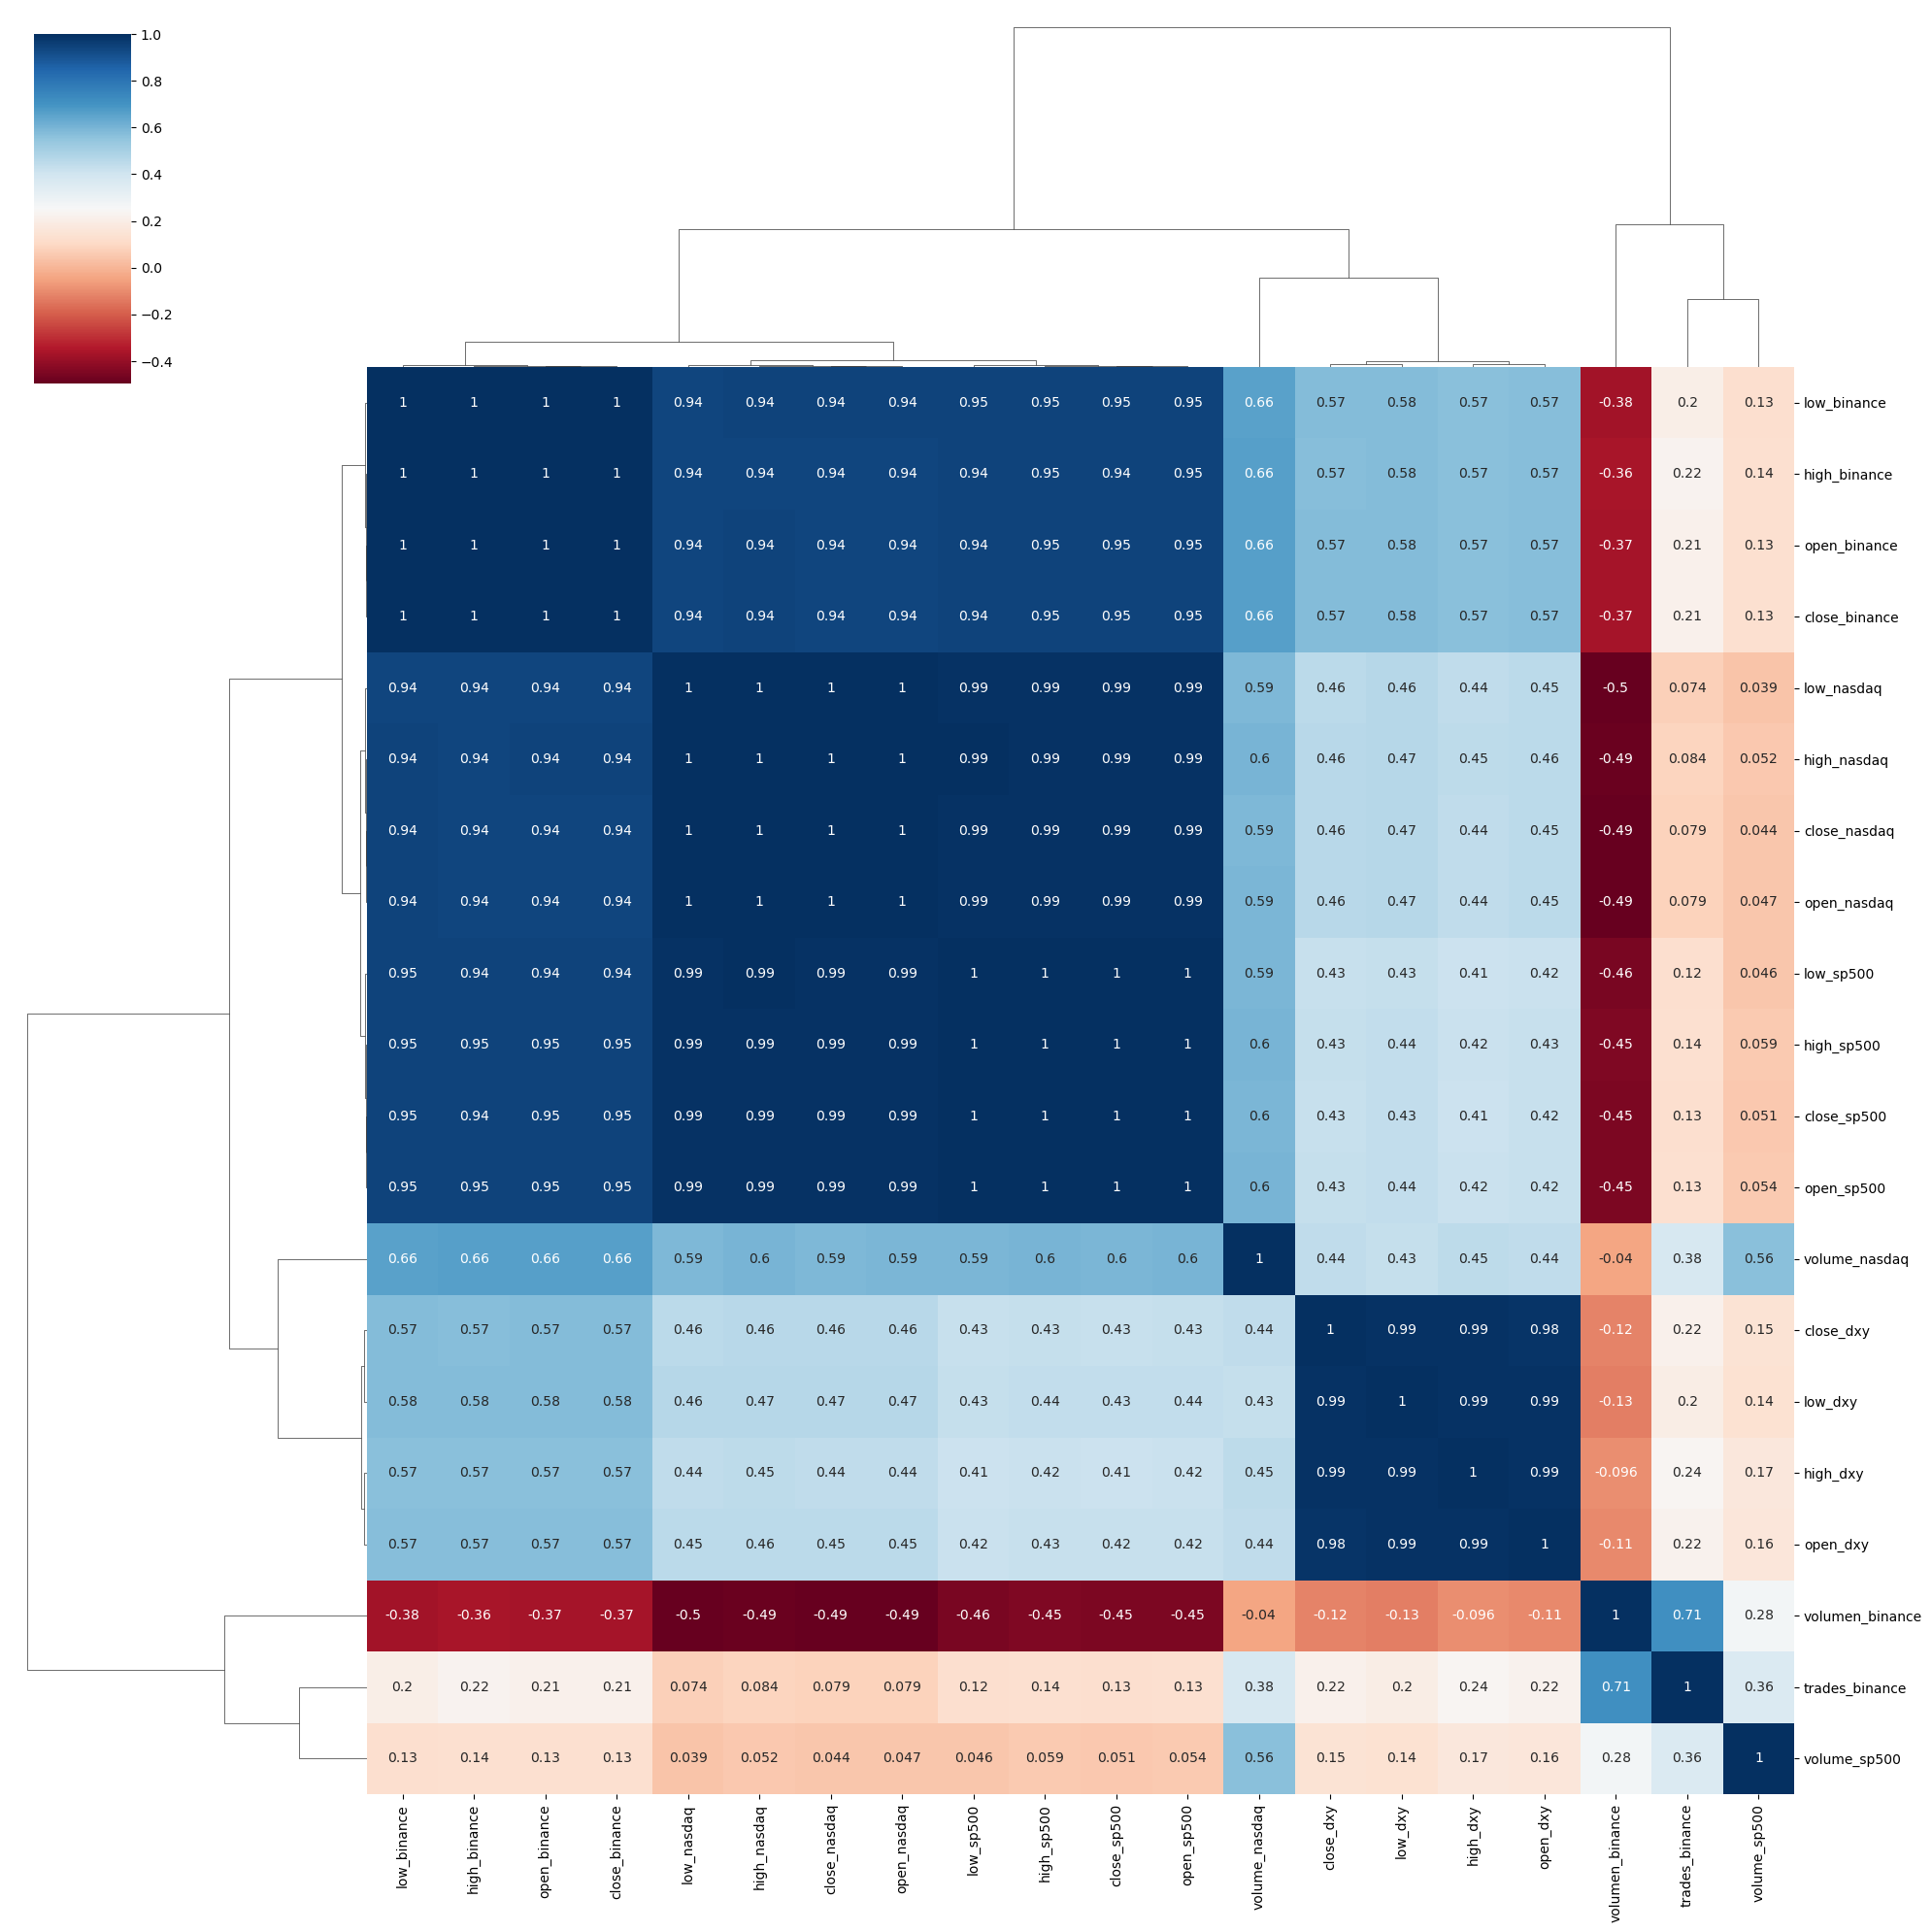

In [7]:
# Aplicar clustermap de la correlación
g = sns.clustermap(corr_matrix, 
                   method='complete',  # Método de enlace para la jerarquía
                   cmap='RdBu',         # Colormap
                   annot=True,          # Mostrar los valores de correlación en el mapa
                   annot_kws={'size': 10}, # Tamaño de la fuente de las anotaciones
                   figsize=(20, 20))     # Tamaño de la figura

# Mostrar el gráfico
plt.show()

### Tendencias en sentimientos del mercado (Fear & Greed Index, Google Trends)

In [8]:
corr_matrix = df[["close_binance", "volatilidad_50_binance", "volatilidad_200_binance", "var_diaria_binance",
                  "fear_greed_index_fg", "bitcoin_gtrends",
                  "close_sp500", "close_nasdaq", "close_dxy"]].dropna().corr(method='spearman')

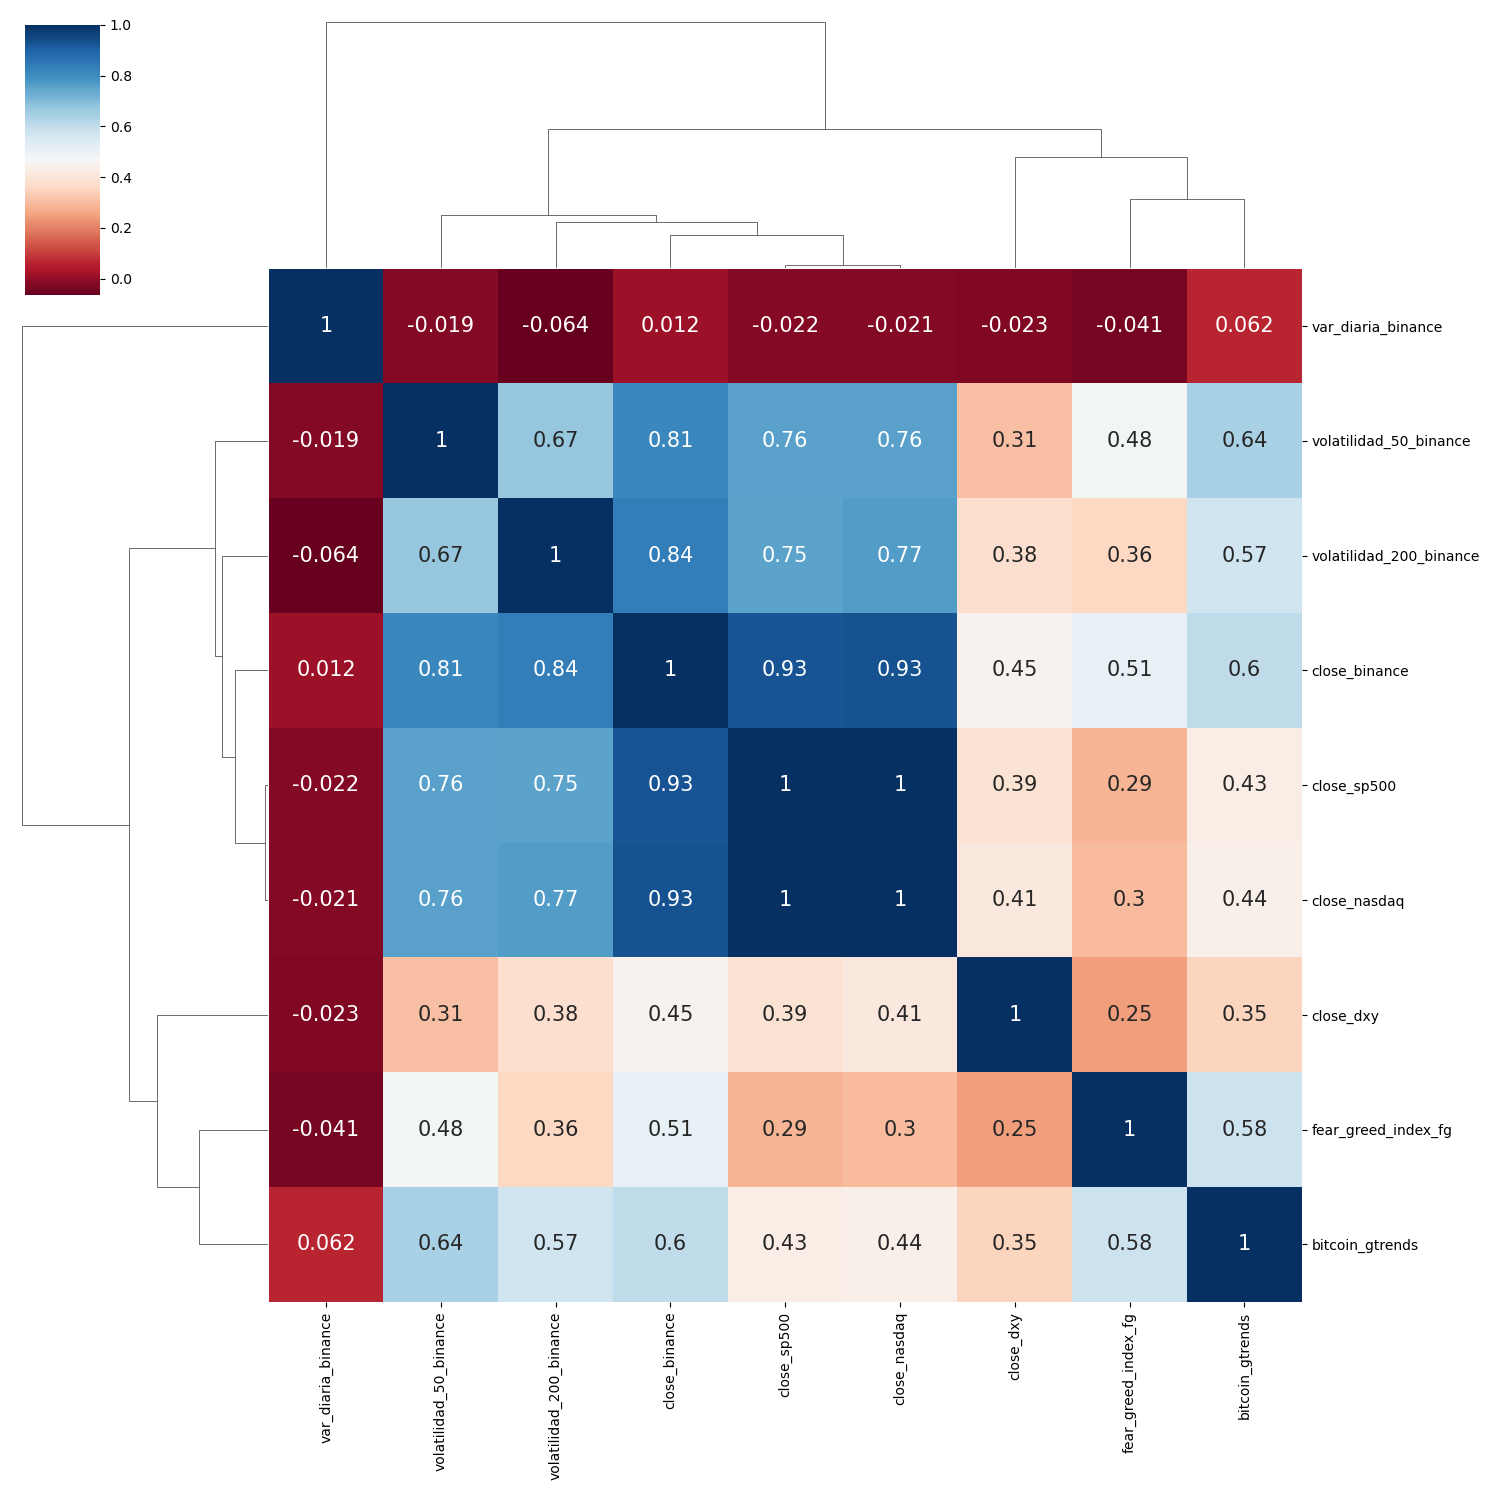

In [9]:
# Aplicar clustermap de la correlación
g = sns.clustermap(corr_matrix, 
                   method='complete',  # Método de enlace para la jerarquía
                   cmap='RdBu',         # Colormap
                   annot=True,          # Mostrar los valores de correlación en el mapa
                   annot_kws={'size': 15}, # Tamaño de la fuente de las anotaciones
                   figsize=(15, 15))     # Tamaño de la figura

# Mostrar el gráfico
plt.show()

### Relación entre volatilidad y precio

In [10]:
df_filtered = df[['timestamp', 'close_binance', 'volatilidad_50_binance', 'volatilidad_200_binance', 'var_diaria_binance']].dropna()

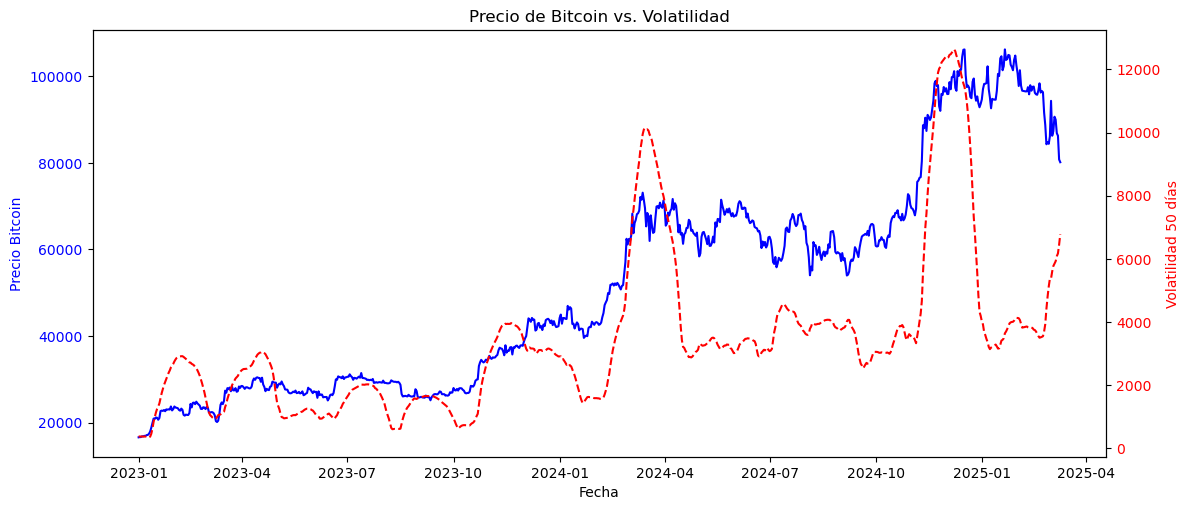

In [11]:
fig, ax1 = plt.subplots(figsize=(12, 5))

# Gráfica de precio (eje izquierdo)
ax1.set_xlabel('Fecha')
ax1.set_ylabel('Precio Bitcoin', color='blue')
ax1.plot(df_filtered['timestamp'], df_filtered['close_binance'], color='blue', label='Precio BTC')
ax1.tick_params(axis='y', labelcolor='blue')

# Agregar segundo eje Y para volatilidad
ax2 = ax1.twinx()
ax2.set_ylabel('Volatilidad 50 días', color='red')
ax2.plot(df_filtered['timestamp'], df_filtered['volatilidad_50_binance'], color='red', linestyle='dashed', label='Volatilidad 50 días')
ax2.tick_params(axis='y', labelcolor='red')

fig.tight_layout()
plt.title("Precio de Bitcoin vs. Volatilidad")
plt.show()

In [12]:
corr_matrix = df_filtered.drop(columns=['timestamp']).corr(method='spearman')  # Spearman capta relaciones no lineales

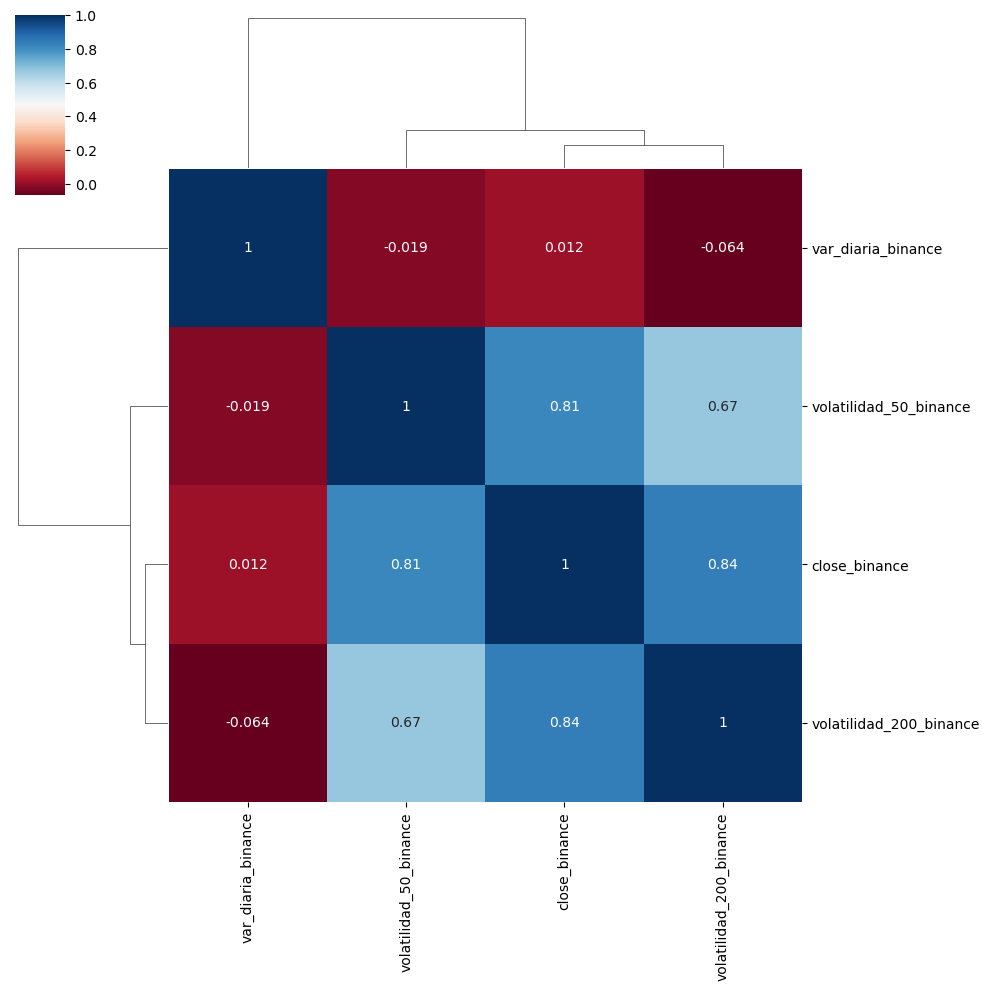

In [13]:
# Aplicar clustermap de la correlación
g = sns.clustermap(corr_matrix, 
                   method='complete',  # Método de enlace para la jerarquía
                   cmap='RdBu',         # Colormap
                   annot=True,          # Mostrar los valores de correlación en el mapa
                   annot_kws={'size': 10}, # Tamaño de la fuente de las anotaciones
                   figsize=(10, 10))     # Tamaño de la figura

# Mostrar el gráfico
plt.show()